In [37]:
import pandas as pd

df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")

df_train.head()

,ID,Sex,Greutate,Lungime_urechi,Ureche_lăsată,Culoare,Vârstă,Tip_blană,Calitate_blană,Formă_corp,Apare_gușa,Sănătate,Scor_jurizare
0,542,Femelă,1.6,19.1,False,Havana,9,Scurtă,Excelentă,Incorectă,False,Probleme_grave_de_sănătate,0
1,441,Mascul,2.7,22.1,False,Agouti,18,Lungă,Excelentă,Aproape_corectă,False,Probleme_grave_de_sănătate,0
2,483,Femelă,7.7,42.3,True,Alb,10,Lungă,Foarte_bună,Corectă,False,Ușoare_probleme_de_sănătate,93
3,423,Femelă,1.8,19.8,False,Havana,10,Scurtă,Foarte_bună,Incorectă,False,Probleme_grave_de_sănătate,0
4,779,Femelă,7.7,42.4,True,Havana,11,Lungă,Foarte_bună,Incorectă,True,Aspect_neîngrijit,82


In [38]:
subtask1 = len(df_test[(df_test["Ureche_lăsată"] == True) & (df_test["Culoare"] == "Havana") & (df_test["Sex"] == "Femelă")])

df_1 = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": 1,
    "answer": [subtask1]
})

df_1

,subtaskID,datapointID,answer
0,1,1,11


In [39]:
#preprocesare simpla

df_train.Sex = df_train.Sex.map({"Mascul": 0, "Femelă": 1})
df_test.Sex = df_test.Sex.map({"Mascul": 0, "Femelă": 1})

df_train.Tip_blană = df_train.Tip_blană.map({"Scurtă": 0, "Lungă": 1})
df_test.Tip_blană = df_test.Tip_blană.map({"Scurtă": 0, "Lungă": 1})

df_train.Calitate_blană = df_train.Calitate_blană.map({"Bună": 0, "Foarte_bună": 1, "Excelentă": 2})
df_test.Calitate_blană = df_test.Calitate_blană.map({"Bună": 0, "Foarte_bună": 1, "Excelentă": 2})

df_train.Formă_corp = df_train.Formă_corp.map({"Incorectă": 0, "Aproape_corectă": 1, "Corectă": 2})
df_test.Formă_corp = df_test.Formă_corp.map({"Incorectă": 0, "Aproape_corectă": 1, "Corectă": 2})

df_train.Sănătate = df_train.Sănătate.map({"Probleme_grave_de_sănătate": 0, "Ușoare_probleme_de_sănătate": 1, "Aspect_neîngrijit": 2, "Sănătos": 3})
df_test.Sănătate = df_test.Sănătate.map({"Probleme_grave_de_sănătate": 0, "Ușoare_probleme_de_sănătate": 1, "Aspect_neîngrijit": 2, "Sănătos": 3})

from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_train.Culoare = enc.fit_transform(df_train.Culoare)
df_test.Culoare = enc.transform(df_test.Culoare)

df_train.head()

,ID,Sex,Greutate,Lungime_urechi,Ureche_lăsată,Culoare,Vârstă,Tip_blană,Calitate_blană,Formă_corp,Apare_gușa,Sănătate,Scor_jurizare
0,542,1,1.6,19.1,False,3,9,0,2,0,False,0,0
1,441,0,2.7,22.1,False,0,18,1,2,1,False,0,0
2,483,1,7.7,42.3,True,1,10,1,1,2,False,1,93
3,423,1,1.8,19.8,False,3,10,0,1,0,False,0,0
4,779,1,7.7,42.4,True,3,11,1,1,0,True,2,82


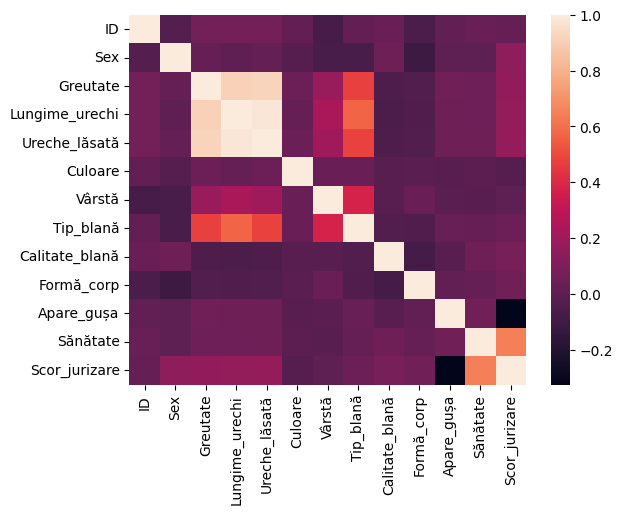

<Figure size 300x300 with 0 Axes>

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(df_train.corr())
plt.figure(figsize=(3, 3))

plt.show()

In [44]:
df_test.columns

Index(['ID', 'Sex', 'Greutate', 'Lungime_urechi', 'Ureche_lăsată', 'Culoare',
       'Vârstă', 'Tip_blană', 'Calitate_blană', 'Formă_corp', 'Apare_gușa',
       'Sănătate'],
      dtype='object')

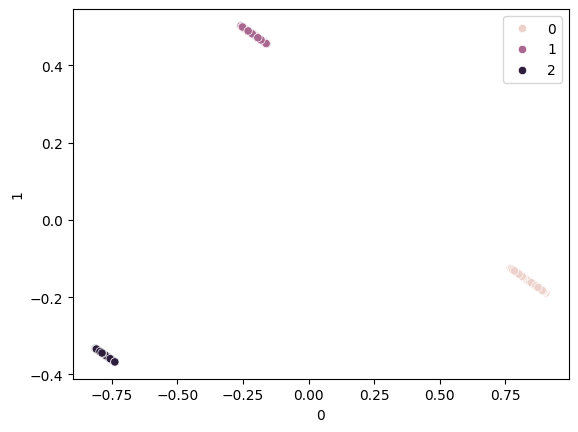

In [64]:
app_features = ['Lungime_urechi', 'Ureche_lăsată', 'Tip_blană'] #am testat mai multe combinatii
X_app = df_test[app_features]

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_app = scaler.fit_transform(X_app)

from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=40)
labels = kmeans.fit_predict(X_app)

from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_decom = pd.DataFrame(pca.fit_transform(X_app))

sns.scatterplot(x=X_decom[0], y=X_decom[1], hue=labels)
plt.show()

In [65]:
df_2 = pd.DataFrame({
    "subtaskID": 2,
    "datapointID": df_test.ID,
    "answer": labels
})

df_2.head()

,subtaskID,datapointID,answer
0,2,522,1
1,2,738,1
2,2,741,0
3,2,661,2
4,2,412,1


In [69]:
df_train.columns

Index(['ID', 'Sex', 'Greutate', 'Lungime_urechi', 'Ureche_lăsată', 'Culoare',
       'Vârstă', 'Tip_blană', 'Calitate_blană', 'Formă_corp', 'Apare_gușa',
       'Sănătate', 'Scor_jurizare'],
      dtype='object')

In [70]:
features = ['Sex', 'Greutate', 'Lungime_urechi', 'Ureche_lăsată', 'Culoare', 'Vârstă', 'Tip_blană', 'Calitate_blană', 'Formă_corp', 'Apare_gușa', 'Sănătate']
target = 'Scor_jurizare'

X = df_train[features]
y = df_train[target]
X_final = df_test[features]

X.head()

,Sex,Greutate,Lungime_urechi,Ureche_lăsată,Culoare,Vârstă,Tip_blană,Calitate_blană,Formă_corp,Apare_gușa,Sănătate
0,1,1.6,19.1,False,3,9,0,2,0,False,0
1,0,2.7,22.1,False,0,18,1,2,1,False,0
2,1,7.7,42.3,True,1,10,1,1,2,False,1
3,1,1.8,19.8,False,3,10,0,1,0,False,0
4,1,7.7,42.4,True,3,11,1,1,0,True,2


In [77]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

model = RandomForestRegressor(random_state=42)

cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error').mean()

-1.0503272857142854

In [78]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [79]:
df_3 = pd.DataFrame({
    "subtaskID": 3,
    "datapointID": df_test.ID,
    "answer": y_preds
})

df_3.head()

,subtaskID,datapointID,answer
0,3,522,0.00
1,3,738,0.00
2,3,741,94.51
3,3,661,64.96
4,3,412,84.01


In [80]:
submission = pd.concat([df_1, df_2, df_3])
submission

,subtaskID,datapointID,answer
0,1,1,11.00
0,2,522,1.00
1,2,738,1.00
2,2,741,0.00
3,2,661,2.00
...,...,...,...
295,3,469,79.97
296,3,936,0.00
297,3,429,0.00
298,3,8,74.00


In [81]:
submission.to_csv("submission.csv", index=False)